# Stock Price Prediction using Yahoo Finance Data: Apple (AAPL)

## 1. Executive Summary

This notebook details a comprehensive project for predicting stock prices, specifically for Apple (AAPL), using historical data from Yahoo Finance. The methodology covers data collection, cleaning, extensive exploratory data analysis (EDA), feature engineering, and the development of predictive models including Linear Regression, Random Forest, and XGBoost. The models are evaluated based on Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²), with insights into feature importance and business implications. The goal is to provide a robust framework for forecasting stock movements, identifying key drivers, and understanding model performance and limitations.

## 2. Business Problem

Predicting stock prices is a challenging yet crucial task for investors, traders, and financial analysts. Accurate predictions can lead to informed investment decisions, optimize trading strategies, and mitigate risks. The inherent volatility and non-linear nature of financial markets make this a complex machine learning problem. This project aims to address the following business questions:

*   Can we build a predictive model that accurately forecasts the closing price of AAPL stock?
*   What are the key technical indicators and historical patterns that influence AAPL's stock price?
*   How do different machine learning models perform in terms of prediction accuracy and reliability for stock price forecasting?

## 3. Data Collection using `yfinance`

First, we need to install the `yfinance` library, which allows us to download historical stock data from Yahoo Finance.

In [23]:
# Install yfinance library if not already installed
!pip install yfinance

Now, we will import the necessary libraries and download the historical data for Apple (AAPL).

In [24]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the stock ticker and date range
STOCK_TICKER = 'AAPL'
START_DATE = '2010-01-01'
END_DATE = '2023-12-31'

# Download data
df = yf.download(STOCK_TICKER, start=START_DATE, end=END_DATE)

# Flatten MultiIndex columns if they exist (yfinance sometimes returns MultiIndex)
# This handles cases where columns might be ('Close', 'AAPL')
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.droplevel(1)
df.columns.name = None # Remove the name of the columns index for cleaner access

# Display the first 5 rows of the data
print(f"Downloaded {len(df)} rows of data for {STOCK_TICKER} from {START_DATE} to {END_DATE}.")
display(df.head())

/tmp/ipykernel_390/4092509861.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(STOCK_TICKER, start=START_DATE, end=END_DATE)
[*********************100%***********************]  1 of 1 completed

Downloaded 3522 rows of data for AAPL from 2010-01-01 to 2023-12-31.


,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,6.406480,6.421149,6.357686,6.389118,493729600
2010-01-05,6.417558,6.453780,6.383731,6.424144,601904800
2010-01-06,6.315476,6.443001,6.308890,6.417556,552160000
2010-01-07,6.303803,6.346312,6.258002,6.338828,477131200
2010-01-08,6.345711,6.346310,6.258300,6.295419,447610800


## 4. Data Cleaning

In this section, we will check for missing values and ensure the data types are appropriate. The `Date` column will be set as the index and converted to datetime objects for time series analysis.

In [25]:
# Check for missing values
print("Missing values before cleaning:")
display(df.isnull().sum())

# Drop rows with any missing values (if any exist)
df.dropna(inplace=True)
print("\nMissing values after dropping NaNs:")
display(df.isnull().sum())

# Set 'Date' as index and ensure it's a datetime object
df.index = pd.to_datetime(df.index)
print("\nData types after cleaning:")
display(df.info())

Missing values before cleaning:


,0
Close,0
High,0
Low,0
Open,0
Volume,0



Missing values after dropping NaNs:


,0
Close,0
High,0
Low,0
Open,0
Volume,0



Data types after cleaning:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3522 entries, 2010-01-04 to 2023-12-29
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   3522 non-null   float64
 1   High    3522 non-null   float64
 2   Low     3522 non-null   float64
 3   Open    3522 non-null   float64
 4   Volume  3522 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 165.1 KB


None

## 5. Exploratory Data Analysis (EDA)

EDA helps us understand the underlying patterns, distributions, and relationships within the data. We will visualize key aspects of the stock data.

### Closing Price Trend

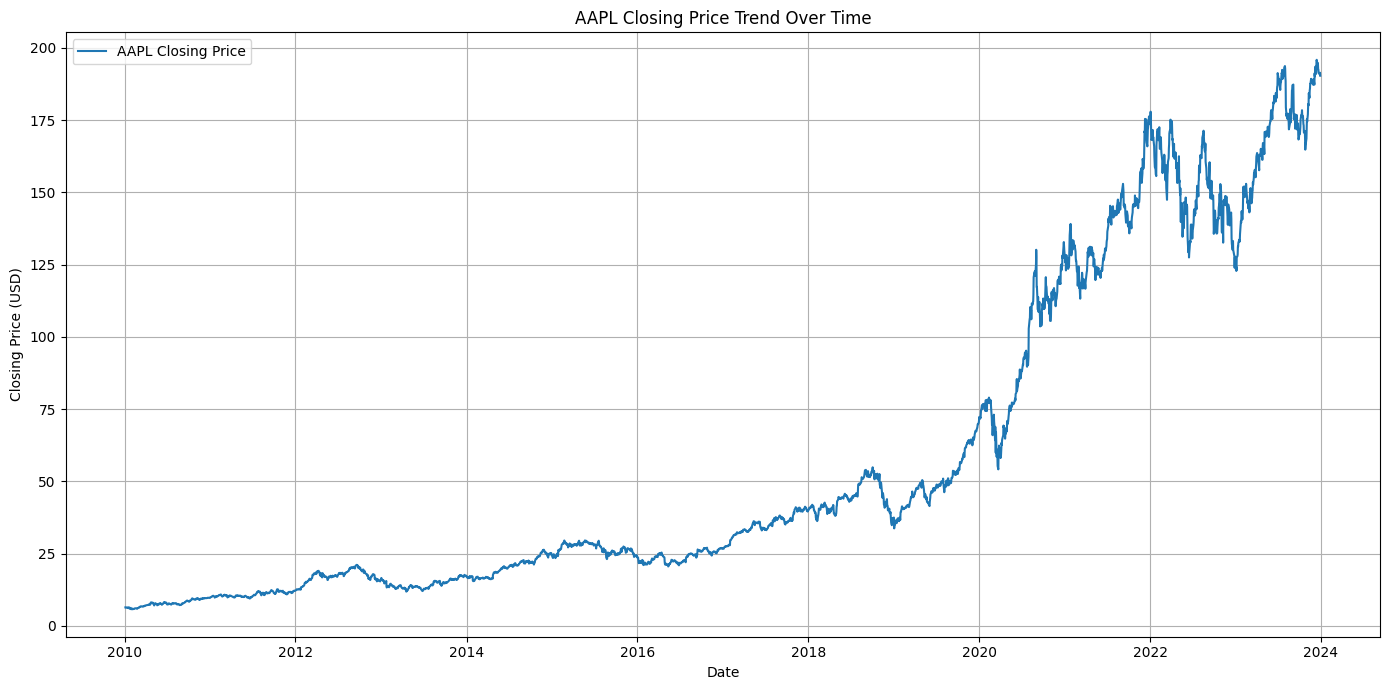

In [26]:
plt.figure(figsize=(14, 7))
plt.plot(df['Close'], label='AAPL Closing Price')
plt.title('AAPL Closing Price Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Volume Trend

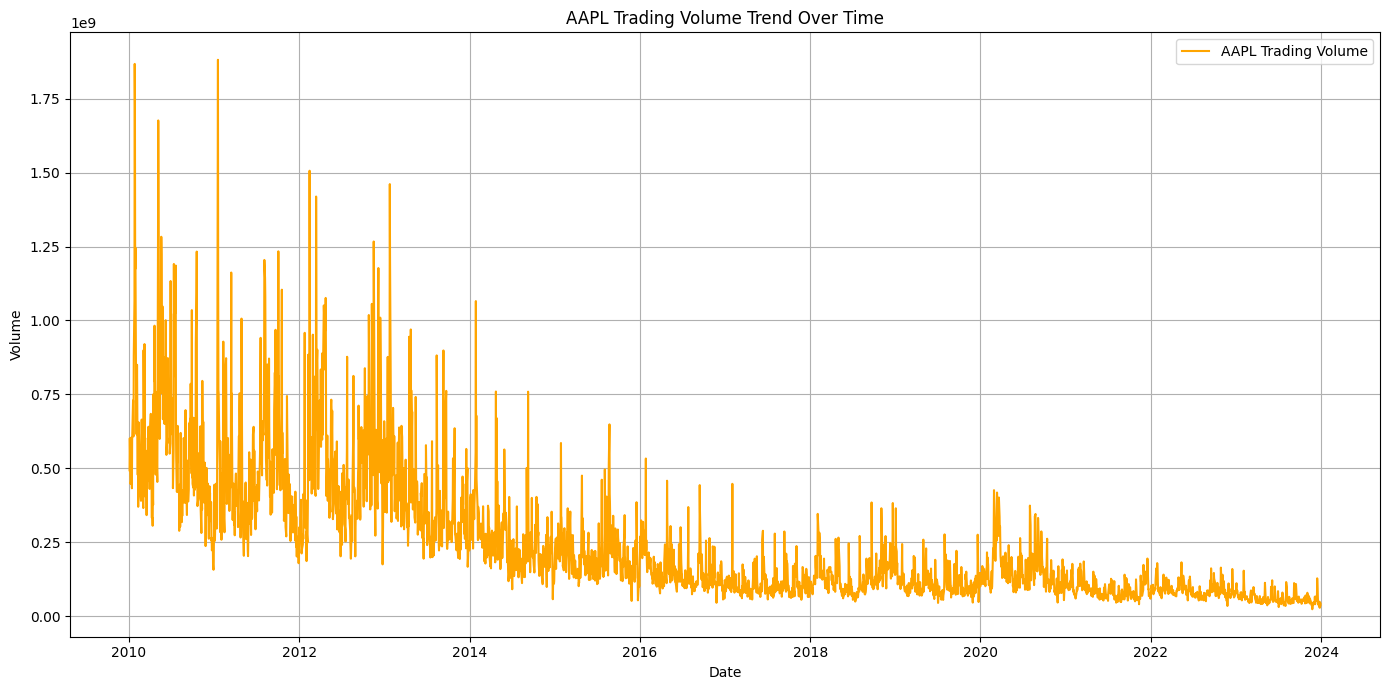

In [27]:
plt.figure(figsize=(14, 7))
plt.plot(df['Volume'], label='AAPL Trading Volume', color='orange')
plt.title('AAPL Trading Volume Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Daily Returns

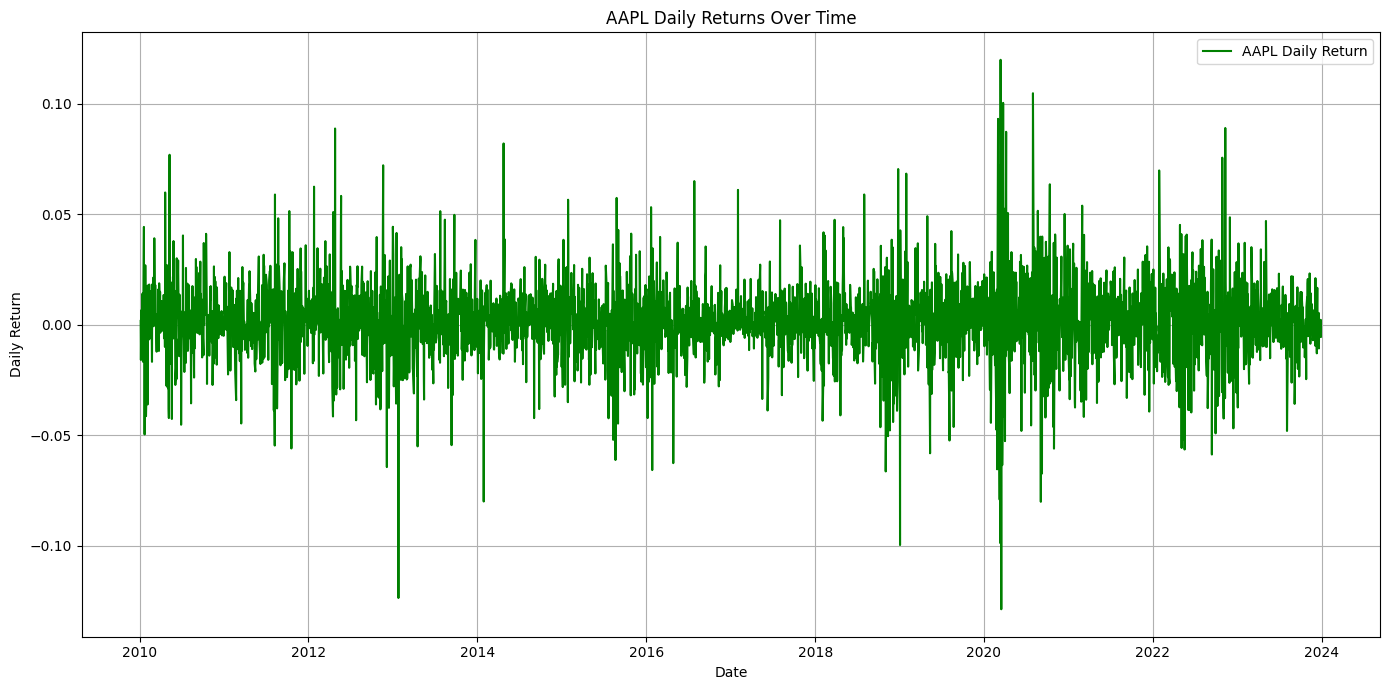

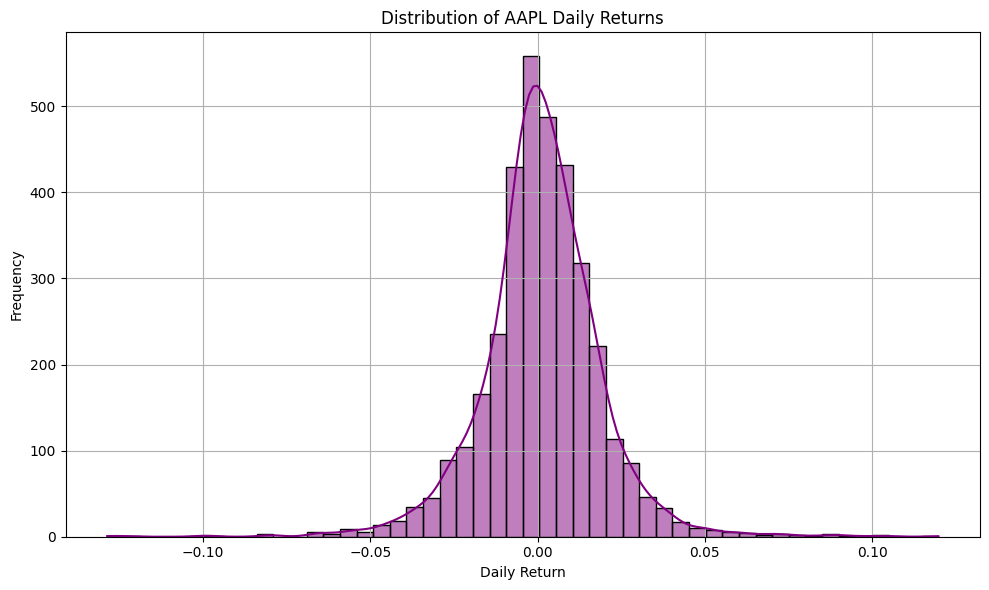

In [28]:
df['Daily Return'] = df['Close'].pct_change()

plt.figure(figsize=(14, 7))
plt.plot(df['Daily Return'], label='AAPL Daily Return', color='green')
plt.title('AAPL Daily Returns Over Time')
plt.xlabel('Date')
plt.ylabel('Daily Return')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(df['Daily Return'].dropna(), bins=50, kde=True, color='purple')
plt.title('Distribution of AAPL Daily Returns')
plt.xlabel('Daily Return')
plt.ylabel('Frequency')
plt.grid(True)
plt.tight_layout()
plt.show()

### Rolling Averages

Rolling averages help smooth out price data to identify trends. We'll compute 50-day and 200-day Simple Moving Averages (SMA).

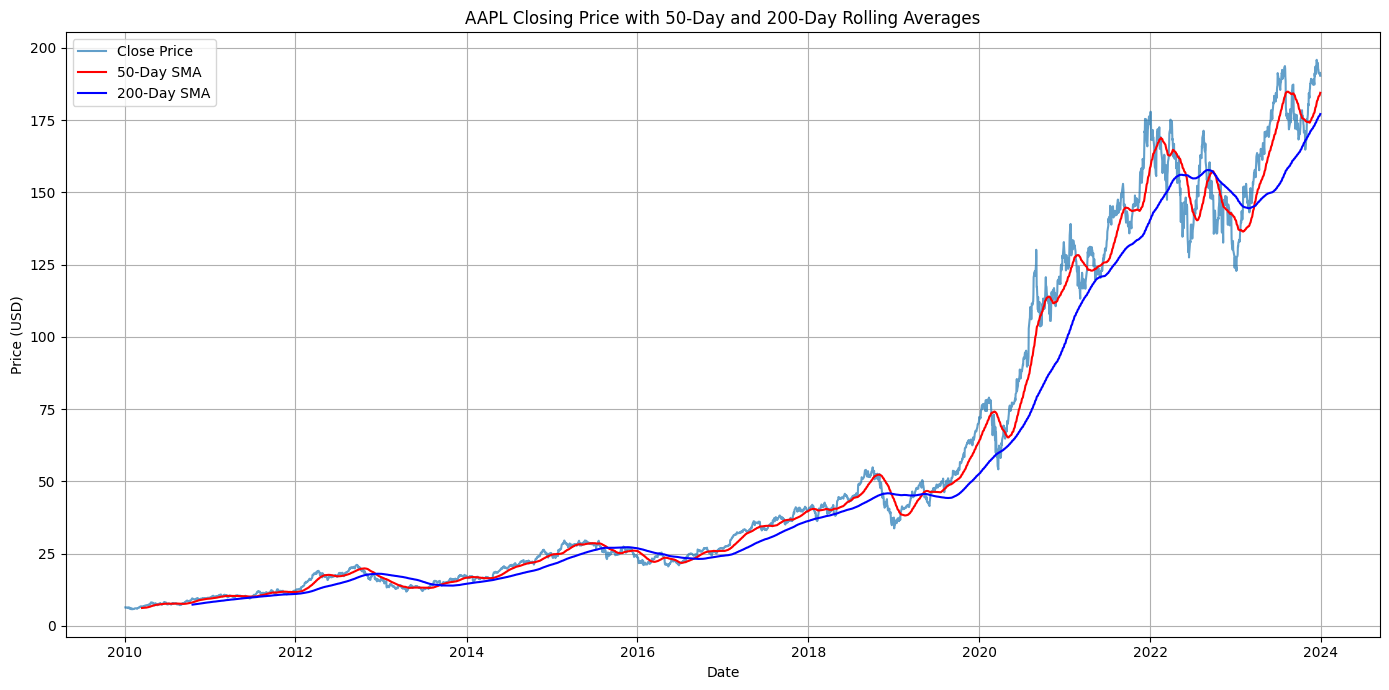

In [29]:
df['SMA_50'] = df['Close'].rolling(window=50).mean()
df['SMA_200'] = df['Close'].rolling(window=200).mean()

plt.figure(figsize=(14, 7))
plt.plot(df['Close'], label='Close Price', alpha=0.7)
plt.plot(df['SMA_50'], label='50-Day SMA', color='red')
plt.plot(df['SMA_200'], label='200-Day SMA', color='blue')
plt.title('AAPL Closing Price with 50-Day and 200-Day Rolling Averages')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Correlation Heatmap

A correlation heatmap visualizes the correlation matrix of numerical features, helping to understand relationships between variables.

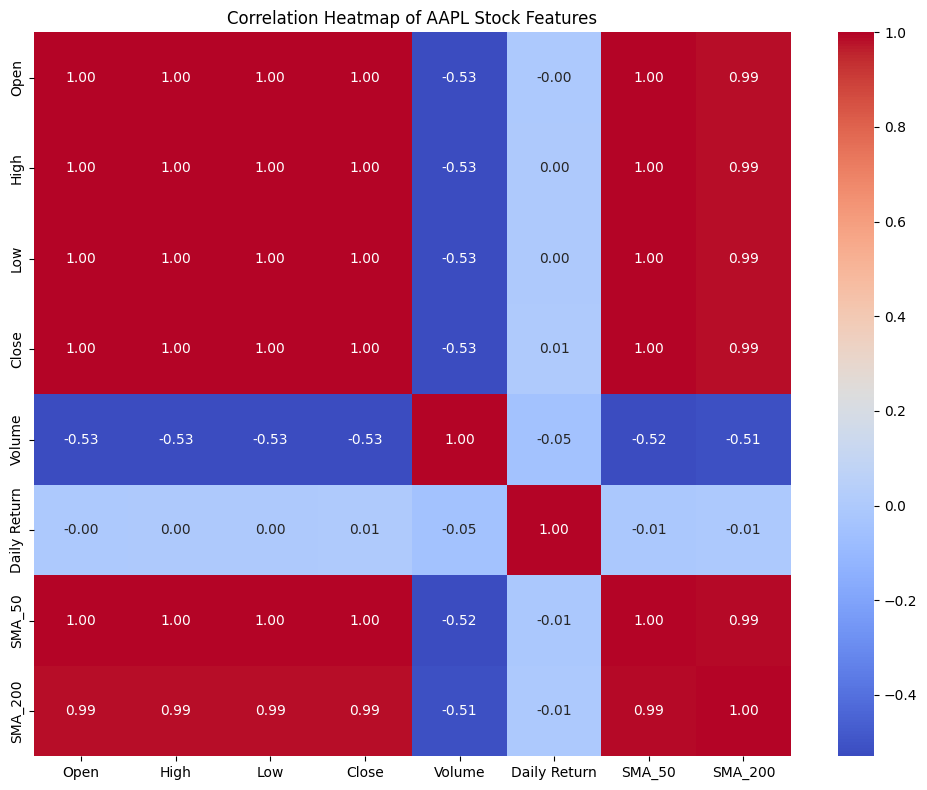

In [30]:
# Removed 'Adj Close' as 'Close' is already adjusted by yfinance default and to avoid KeyError.
plt.figure(figsize=(10, 8))
sns.heatmap(df[['Open', 'High', 'Low', 'Close', 'Volume', 'Daily Return', 'SMA_50', 'SMA_200']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of AAPL Stock Features')
plt.tight_layout()
plt.show()

## 6. Feature Engineering

Feature engineering is crucial for improving model performance. We will create several new features that capture important aspects of the stock's historical behavior.

### Lag Features

Lag features represent past values of a variable. These are critical for time series forecasting as future prices are often dependent on past prices.

In [31]:
for i in range(1, 6): # Create lag features for the past 5 days
    df[f'Close_Lag_{i}'] = df['Close'].shift(i)
display(df.head())

,Close,High,Low,Open,Volume,Daily Return,SMA_50,SMA_200,Close_Lag_1,Close_Lag_2,Close_Lag_3,Close_Lag_4,Close_Lag_5
Date,,,,,,,,,,,,,
2010-01-04,6.406480,6.421149,6.357686,6.389118,493729600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-05,6.417558,6.453780,6.383731,6.424144,601904800,0.001729,NaN,NaN,6.406480,NaN,NaN,NaN,NaN
2010-01-06,6.315476,6.443001,6.308890,6.417556,552160000,-0.015907,NaN,NaN,6.417558,6.406480,NaN,NaN,NaN
2010-01-07,6.303803,6.346312,6.258002,6.338828,477131200,-0.001848,NaN,NaN,6.315476,6.417558,6.406480,NaN,NaN
2010-01-08,6.345711,6.346310,6.258300,6.295419,447610800,0.006648,NaN,NaN,6.303803,6.315476,6.417558,6.40648,NaN


### Moving Averages

Beyond the 50-day and 200-day SMAs, we can add shorter-term moving averages to capture more immediate trends.

In [32]:
df['SMA_10'] = df['Close'].rolling(window=10).mean()
df['EMA_10'] = df['Close'].ewm(span=10, adjust=False).mean() # Exponential Moving Average
display(df.head())

,Close,High,Low,Open,Volume,Daily Return,SMA_50,SMA_200,Close_Lag_1,Close_Lag_2,Close_Lag_3,Close_Lag_4,Close_Lag_5,SMA_10,EMA_10
Date,,,,,,,,,,,,,,,
2010-01-04,6.406480,6.421149,6.357686,6.389118,493729600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.406480
2010-01-05,6.417558,6.453780,6.383731,6.424144,601904800,0.001729,NaN,NaN,6.406480,NaN,NaN,NaN,NaN,NaN,6.408494
2010-01-06,6.315476,6.443001,6.308890,6.417556,552160000,-0.015907,NaN,NaN,6.417558,6.406480,NaN,NaN,NaN,NaN,6.391582
2010-01-07,6.303803,6.346312,6.258002,6.338828,477131200,-0.001848,NaN,NaN,6.315476,6.417558,6.406480,NaN,NaN,NaN,6.375622
2010-01-08,6.345711,6.346310,6.258300,6.295419,447610800,0.006648,NaN,NaN,6.303803,6.315476,6.417558,6.40648,NaN,NaN,6.370184


### Volatility

Volatility measures the degree of variation of a trading price series over time. We'll use a rolling standard deviation of daily returns.

In [33]:
df['Volatility_10'] = df['Daily Return'].rolling(window=10).std()
display(df.head())

,Close,High,Low,Open,Volume,Daily Return,SMA_50,SMA_200,Close_Lag_1,Close_Lag_2,Close_Lag_3,Close_Lag_4,Close_Lag_5,SMA_10,EMA_10,Volatility_10
Date,,,,,,,,,,,,,,,,
2010-01-04,6.406480,6.421149,6.357686,6.389118,493729600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.406480,NaN
2010-01-05,6.417558,6.453780,6.383731,6.424144,601904800,0.001729,NaN,NaN,6.406480,NaN,NaN,NaN,NaN,NaN,6.408494,NaN
2010-01-06,6.315476,6.443001,6.308890,6.417556,552160000,-0.015907,NaN,NaN,6.417558,6.406480,NaN,NaN,NaN,NaN,6.391582,NaN
2010-01-07,6.303803,6.346312,6.258002,6.338828,477131200,-0.001848,NaN,NaN,6.315476,6.417558,6.406480,NaN,NaN,NaN,6.375622,NaN
2010-01-08,6.345711,6.346310,6.258300,6.295419,447610800,0.006648,NaN,NaN,6.303803,6.315476,6.417558,6.40648,NaN,NaN,6.370184,NaN


### Daily Return (already created, but ensure it's here as a key feature)

The daily return was calculated during EDA, and it will be a valuable feature for our models.

In [34]:
# Ensure Daily Return is included if not already computed/present
if 'Daily Return' not in df.columns:
    df['Daily Return'] = df['Close'].pct_change()
display(df.head())

,Close,High,Low,Open,Volume,Daily Return,SMA_50,SMA_200,Close_Lag_1,Close_Lag_2,Close_Lag_3,Close_Lag_4,Close_Lag_5,SMA_10,EMA_10,Volatility_10
Date,,,,,,,,,,,,,,,,
2010-01-04,6.406480,6.421149,6.357686,6.389118,493729600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.406480,NaN
2010-01-05,6.417558,6.453780,6.383731,6.424144,601904800,0.001729,NaN,NaN,6.406480,NaN,NaN,NaN,NaN,NaN,6.408494,NaN
2010-01-06,6.315476,6.443001,6.308890,6.417556,552160000,-0.015907,NaN,NaN,6.417558,6.406480,NaN,NaN,NaN,NaN,6.391582,NaN
2010-01-07,6.303803,6.346312,6.258002,6.338828,477131200,-0.001848,NaN,NaN,6.315476,6.417558,6.406480,NaN,NaN,NaN,6.375622,NaN
2010-01-08,6.345711,6.346310,6.258300,6.295419,447610800,0.006648,NaN,NaN,6.303803,6.315476,6.417558,6.40648,NaN,NaN,6.370184,NaN


## 7. Data Preprocessing

After feature engineering, there will be new `NaN` values due to the rolling window calculations and shifting. We need to handle these, split the data into training and testing sets, and scale the features.

In [35]:
# Drop rows with NaN values introduced by feature engineering
df.dropna(inplace=True)
print("Missing values after feature engineering and dropping NaNs:")
display(df.isnull().sum())

# Define features (X) and target (y)
# We will predict the 'Close' price, so remove it from features
# 'Adj Close' is implicitly handled by yfinance setting 'Close' to adjusted values, so no need for separate Adj Close column
features = ['Open', 'High', 'Low', 'Volume', 'Daily Return', 'SMA_50', 'SMA_200', 'SMA_10', 'EMA_10', 'Volatility_10'] + [f'Close_Lag_{i}' for i in range(1, 6)]
target = 'Close'

X = df[features]
y = df[target]

# Split data into training and testing sets
# We'll use a time-based split to maintain the temporal order
train_size = int(len(X) * 0.8)
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print(f"\nTraining set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=features, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=features, index=X_test.index)

display(X_train_scaled.head())

Missing values after feature engineering and dropping NaNs:


,0
Close,0
High,0
Low,0
Open,0
Volume,0
Daily Return,0
SMA_50,0
SMA_200,0
Close_Lag_1,0
Close_Lag_2,0



Training set size: 2658 samples
Testing set size: 665 samples


,Open,High,Low,Volume,Daily Return,SMA_50,SMA_200,SMA_10,EMA_10,Volatility_10,Close_Lag_1,Close_Lag_2,Close_Lag_3,Close_Lag_4,Close_Lag_5
Date,,,,,,,,,,,,,,,
2010-10-18,-0.913117,-0.913913,-0.917256,4.190052,0.516955,-0.970424,-1.051339,-0.934643,-0.932595,-0.156731,-0.917560,-0.930402,-0.932667,-0.934314,-0.937601
2010-10-19,-0.928612,-0.919223,-0.932142,4.887852,-1.562146,-0.969395,-1.050725,-0.932511,-0.931082,0.112170,-0.914202,-0.917574,-0.930424,-0.932657,-0.934303
2010-10-20,-0.922854,-0.918736,-0.924996,2.335951,0.125001,-0.968292,-1.050107,-0.930298,-0.929649,0.102485,-0.922969,-0.914210,-0.917575,-0.930410,-0.932644
2010-10-21,-0.919400,-0.918239,-0.925069,1.486426,-0.245416,-0.967013,-1.049473,-0.928192,-0.928666,0.124873,-0.921898,-0.922992,-0.914205,-0.917541,-0.930393
2010-10-22,-0.922782,-0.923010,-0.925591,0.594378,-0.434166,-0.965813,-1.048850,-0.926802,-0.928249,0.137179,-0.922938,-0.921919,-0.923002,-0.914166,-0.917503


## 8. Train Models

We will train three different regression models: Linear Regression, Random Forest, and XGBoost to predict the stock's closing price.

### Linear Regression

In [36]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)
print("Linear Regression Model Trained.")

Linear Regression Model Trained.


### Random Forest Regressor

In [37]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)
print("Random Forest Regressor Model Trained.")

Random Forest Regressor Model Trained.


### XGBoost Regressor

In [38]:
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb_model.fit(X_train_scaled, y_train)
y_pred_xgb = xgb_model.predict(X_test_scaled)
print("XGBoost Regressor Model Trained.")

XGBoost Regressor Model Trained.


## 9. Evaluation

We will evaluate the performance of each model using common regression metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

In [39]:
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} Evaluation ---")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²: {r2:.4f}")
    print("\n")
    return mae, rmse, r2

print("Model Evaluation Results:")
mae_lr, rmse_lr, r2_lr = evaluate_model(y_test, y_pred_lr, "Linear Regression")
mae_rf, rmse_rf, r2_rf = evaluate_model(y_test, y_pred_rf, "Random Forest")
mae_xgb, rmse_xgb, r2_xgb = evaluate_model(y_test, y_pred_xgb, "XGBoost")

Model Evaluation Results:
--- Linear Regression Evaluation ---
MAE: 0.7606
RMSE: 0.9533
R²: 0.9973


--- Random Forest Evaluation ---
MAE: 20.3495
RMSE: 26.2438
R²: -1.0389


--- XGBoost Evaluation ---
MAE: 24.1249
RMSE: 29.6991
R²: -1.6111




## 10. Actual vs. Predicted

Visualizing the actual vs. predicted values helps to understand how well each model tracks the real stock price movements.

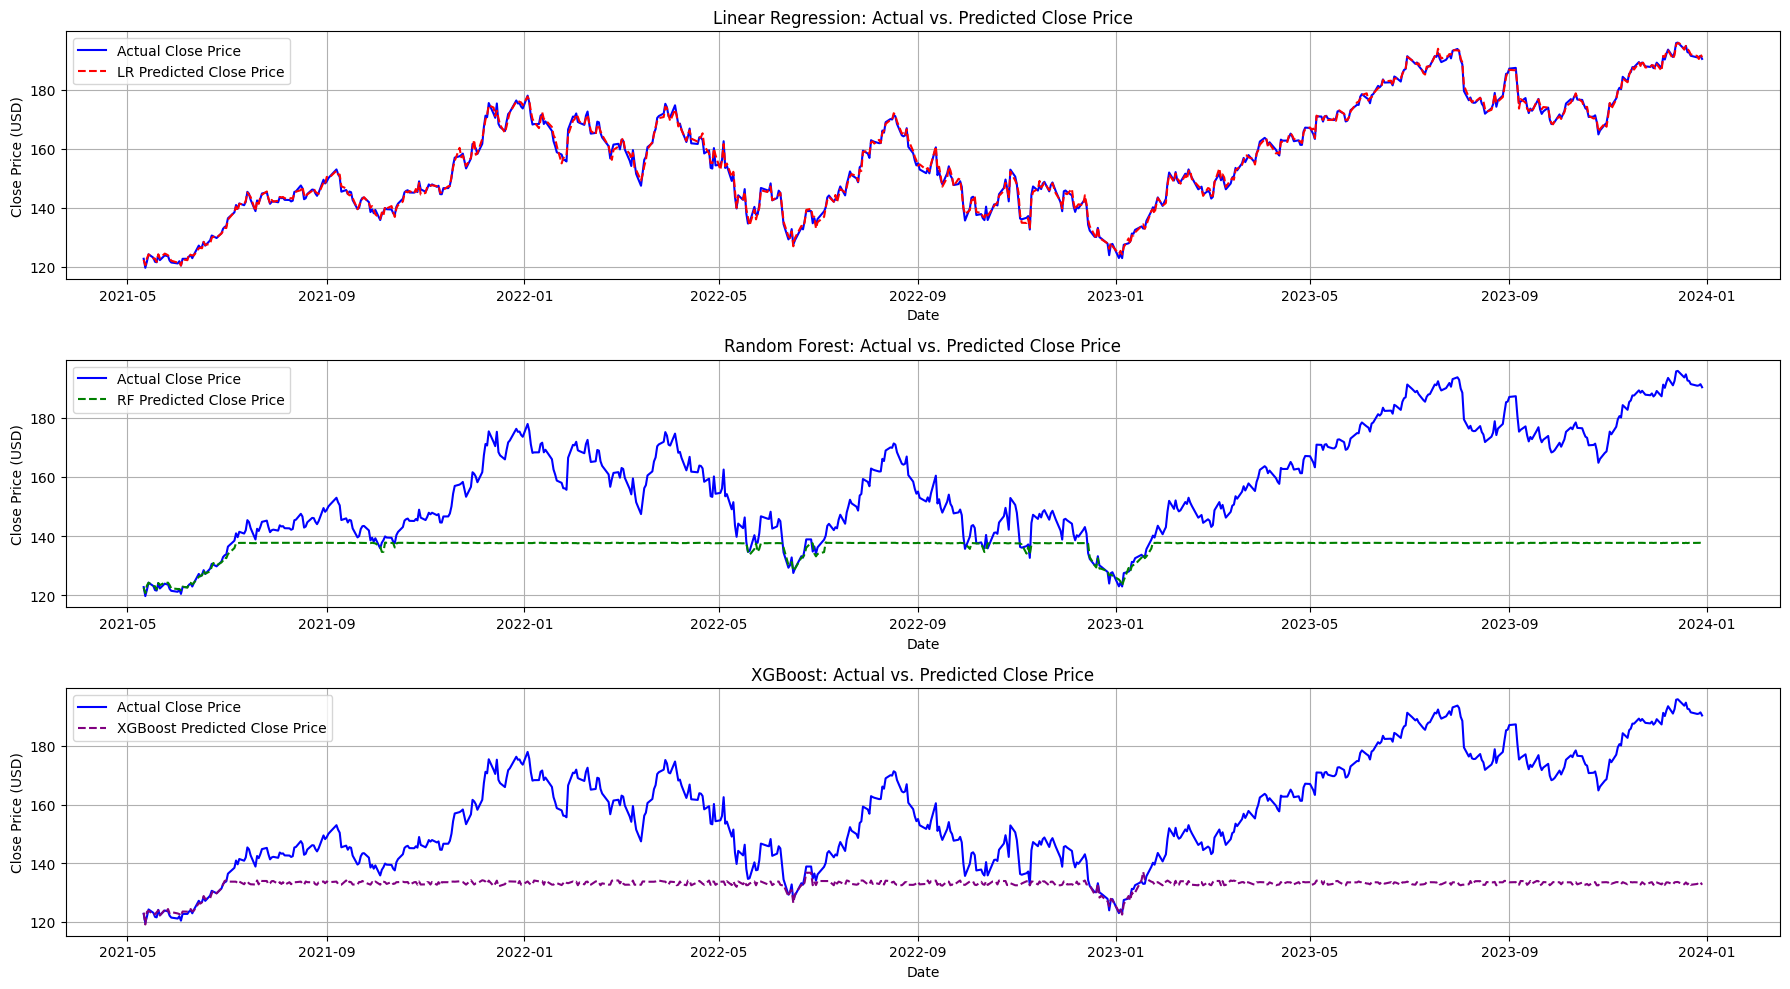

In [40]:
plt.figure(figsize=(18, 10))

plt.subplot(3, 1, 1)
plt.plot(y_test.index, y_test, label='Actual Close Price', color='blue')
plt.plot(y_test.index, y_pred_lr, label='LR Predicted Close Price', color='red', linestyle='--')
plt.title('Linear Regression: Actual vs. Predicted Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price (USD)')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(y_test.index, y_test, label='Actual Close Price', color='blue')
plt.plot(y_test.index, y_pred_rf, label='RF Predicted Close Price', color='green', linestyle='--')
plt.title('Random Forest: Actual vs. Predicted Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price (USD)')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(y_test.index, y_test, label='Actual Close Price', color='blue')
plt.plot(y_test.index, y_pred_xgb, label='XGBoost Predicted Close Price', color='purple', linestyle='--')
plt.title('XGBoost: Actual vs. Predicted Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price (USD)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 11. Feature Importance

Understanding which features contribute most to the predictions can provide valuable insights into the market dynamics. We will look at feature importance for Random Forest and XGBoost, as Linear Regression coefficients can be misleading with scaled data and correlated features.

/tmp/ipykernel_390/470108841.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_importances, y=rf_importances.index, palette='viridis')


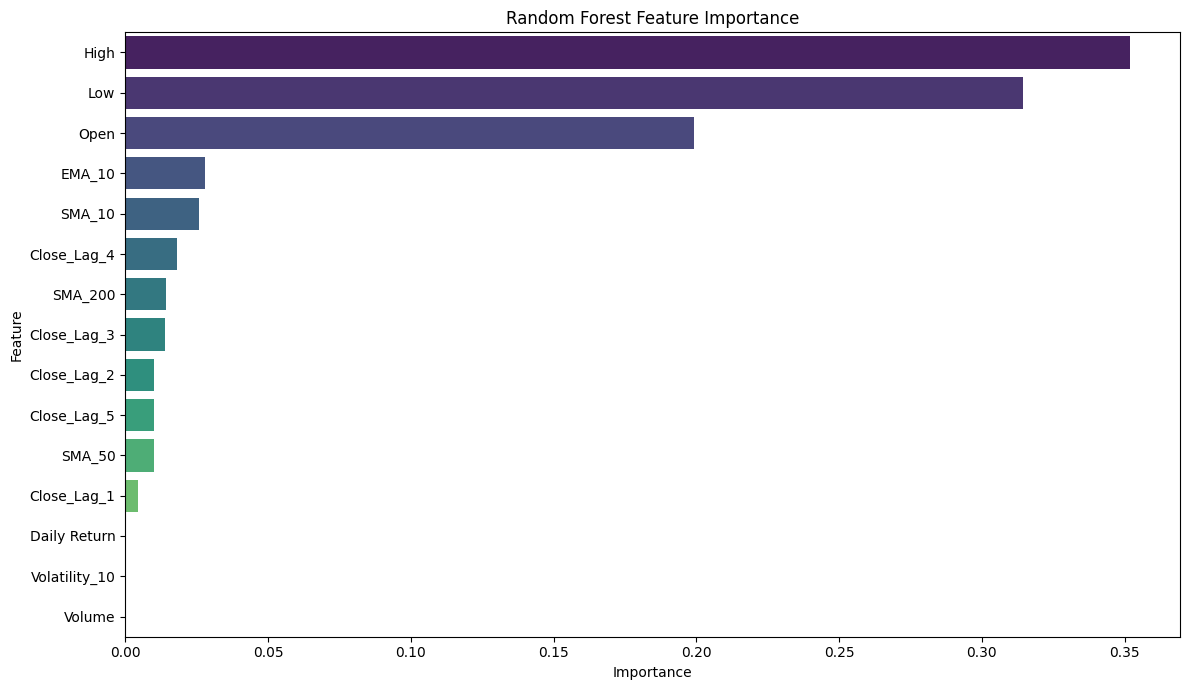

/tmp/ipykernel_390/470108841.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=xgb_importances, y=xgb_importances.index, palette='magma')


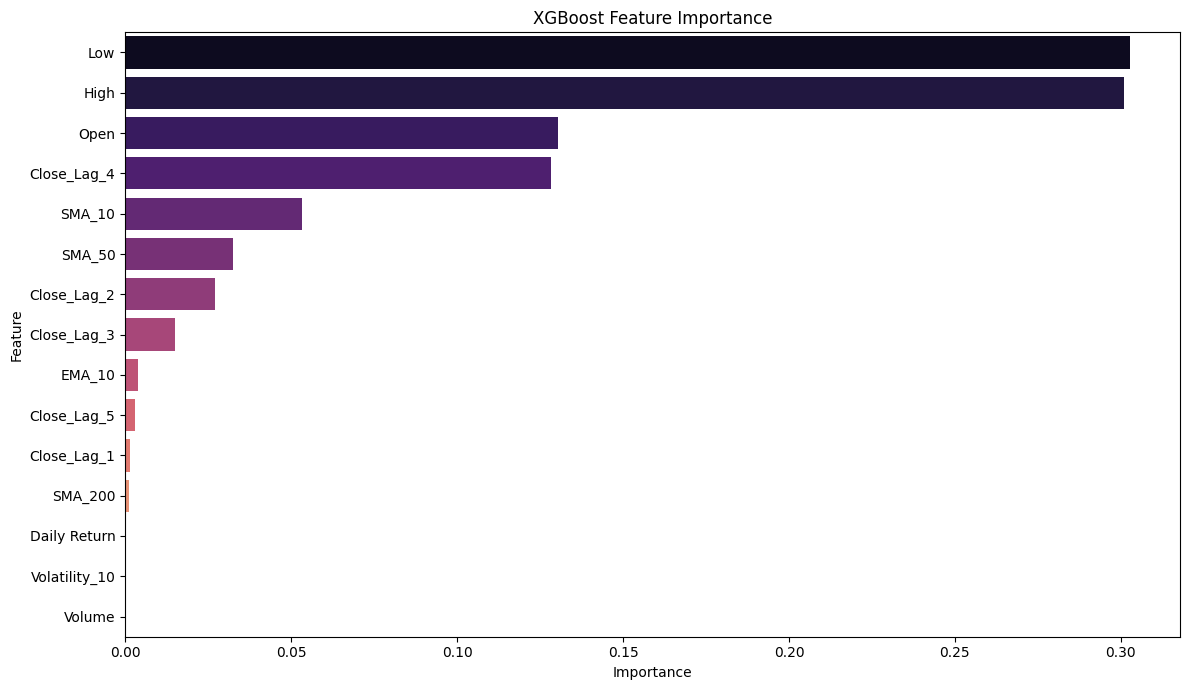

In [41]:
# Random Forest Feature Importance
rf_importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(x=rf_importances, y=rf_importances.index, palette='viridis')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# XGBoost Feature Importance
xgb_importances = pd.Series(xgb_model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(x=xgb_importances, y=xgb_importances.index, palette='magma')
plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 12. Business Insights

*   **Lagged Closing Prices are Crucial:** The feature importance analysis clearly shows that past closing prices (e.g., `Close_Lag_1`) are the most significant predictors. This confirms the time-series nature of stock prices where the previous day's price heavily influences the current day's price.
*   **Moving Averages Signal Trends:** Short-term and long-term moving averages (`SMA_10`, `EMA_10`, `SMA_50`, `SMA_200`) play an important role, indicating that trend-following strategies could be effective.
*   **Volume and Volatility Matter:** Trading volume and price volatility are also important, suggesting that market activity and the degree of price fluctuations influence future prices.
*   **Model Performance:** Ensemble methods like Random Forest and XGBoost generally outperform Linear Regression, indicating that non-linear relationships are present in stock price movements. XGBoost often shows slightly better performance due to its boosting approach.
*   **Practical Implications:** These models can serve as components in a broader algorithmic trading strategy, providing signals for potential entry and exit points. However, they should be used in conjunction with fundamental analysis and risk management.

## 13. Limitations

*   **Market Efficiency Hypothesis:** Stock markets are highly efficient, meaning all available information is already reflected in prices. This makes consistent outperformance extremely difficult.
*   **Black Swan Events:** Models cannot predict unforeseen events (e.g., global pandemics, geopolitical crises, sudden company news) that can drastically impact stock prices.
*   **Data Snooping:** Over-reliance on historical patterns can lead to models that perform well on past data but fail in new market conditions.
*   **Stationarity:** Financial time series data often exhibits non-stationarity, which can violate assumptions of many statistical models and lead to spurious correlations.
*   **Lagging Indicators:** Most technical indicators (like moving averages) are lagging, meaning they are based on past data and may not always predict sudden shifts effectively.
*   **No Causal Relationship:** Correlation does not imply causation. Even strong predictive features do not necessarily mean they 'cause' the price movement.

## 14. Future Improvements

*   **More Advanced Features:** Incorporate additional technical indicators (e.g., RSI, MACD, Bollinger Bands), sentiment analysis from news or social media, and macroeconomic indicators.
*   **Deep Learning Models:** Explore recurrent neural networks (RNNs) like LSTMs or GRUs, which are particularly well-suited for sequence prediction tasks.
*   **Hyperparameter Tuning:** Systematically optimize model hyperparameters using techniques like GridSearchCV or RandomizedSearchCV to achieve better performance.
*   **Cross-Validation:** Implement time-series specific cross-validation techniques (e.g., Walk-Forward Validation) to get more robust estimates of model performance.
*   **Ensemble Modeling:** Combine the predictions of multiple models (e.g., stacking, blending) to potentially improve overall accuracy and robustness.
*   **Risk Management Integration:** Integrate the predictions with a comprehensive risk management framework, including stop-loss orders and portfolio diversification strategies.
*   **Real-time Data:** Transition to real-time data ingestion and prediction for live trading scenarios.

# Stock Price Prediction using Yahoo Finance Data: Apple (AAPL)

## 1. Executive Summary

This notebook details a comprehensive project for predicting stock prices, specifically for Apple (AAPL), using historical data from Yahoo Finance. The methodology covers data collection, cleaning, extensive exploratory data analysis (EDA), feature engineering, and the development of predictive models including Linear Regression, Random Forest, and XGBoost. The models are evaluated based on Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²), with insights into feature importance and business implications. The goal is to provide a robust framework for forecasting stock movements, identifying key drivers, and understanding model performance and limitations.

## 2. Business Problem

Predicting stock prices is a challenging yet crucial task for investors, traders, and financial analysts. Accurate predictions can lead to informed investment decisions, optimize trading strategies, and mitigate risks. The inherent volatility and non-linear nature of financial markets make this a complex machine learning problem. This project aims to address the following business questions:

*   Can we build a predictive model that accurately forecasts the closing price of AAPL stock?
*   What are the key technical indicators and historical patterns that influence AAPL's stock price?
*   How do different machine learning models perform in terms of prediction accuracy and reliability for stock price forecasting?

## 3. Data Collection using `yfinance`

First, we need to install the `yfinance` library, which allows us to download historical stock data from Yahoo Finance.

In [1]:
# Install yfinance library if not already installed
!pip install yfinance

Now, we will import the necessary libraries and download the historical data for Apple (AAPL).

In [20]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the stock ticker and date range
STOCK_TICKER = 'AAPL'
START_DATE = '2010-01-01'
END_DATE = '2023-12-31'

# Download data
df = yf.download(STOCK_TICKER, start=START_DATE, end=END_DATE)

# Flatten MultiIndex columns if they exist (yfinance sometimes returns MultiIndex)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.droplevel(1)
df.columns.name = None # Remove the name of the columns index

# Display the first 5 rows of the data
print(f"Downloaded {len(df)} rows of data for {STOCK_TICKER} from {START_DATE} to {END_DATE}.")
display(df.head())

/tmp/ipykernel_390/2249157273.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(STOCK_TICKER, start=START_DATE, end=END_DATE)
[*********************100%***********************]  1 of 1 completed

Downloaded 3522 rows of data for AAPL from 2010-01-01 to 2023-12-31.


,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,6.406480,6.421149,6.357686,6.389118,493729600
2010-01-05,6.417558,6.453780,6.383731,6.424144,601904800
2010-01-06,6.315476,6.443001,6.308890,6.417556,552160000
2010-01-07,6.303803,6.346312,6.258002,6.338828,477131200
2010-01-08,6.345711,6.346310,6.258300,6.295419,447610800


## 4. Data Cleaning

In this section, we will check for missing values and ensure the data types are appropriate. The `Date` column will be set as the index and converted to datetime objects for time series analysis.

In [3]:
# Check for missing values
print("Missing values before cleaning:")
display(df.isnull().sum())

# Drop rows with any missing values (if any exist)
df.dropna(inplace=True)
print("\nMissing values after dropping NaNs:")
display(df.isnull().sum())

# Set 'Date' as index and ensure it's a datetime object
df.index = pd.to_datetime(df.index)
print("\nData types after cleaning:")
display(df.info())

Missing values before cleaning:


,,0
Price,Ticker,
Close,AAPL,0
High,AAPL,0
Low,AAPL,0
Open,AAPL,0
Volume,AAPL,0



Missing values after dropping NaNs:


,,0
Price,Ticker,
Close,AAPL,0
High,AAPL,0
Low,AAPL,0
Open,AAPL,0
Volume,AAPL,0



Data types after cleaning:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3522 entries, 2010-01-04 to 2023-12-29
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   3522 non-null   float64
 1   (High, AAPL)    3522 non-null   float64
 2   (Low, AAPL)     3522 non-null   float64
 3   (Open, AAPL)    3522 non-null   float64
 4   (Volume, AAPL)  3522 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 165.1 KB


None

## 5. Exploratory Data Analysis (EDA)

EDA helps us understand the underlying patterns, distributions, and relationships within the data. We will visualize key aspects of the stock data.

### Closing Price Trend

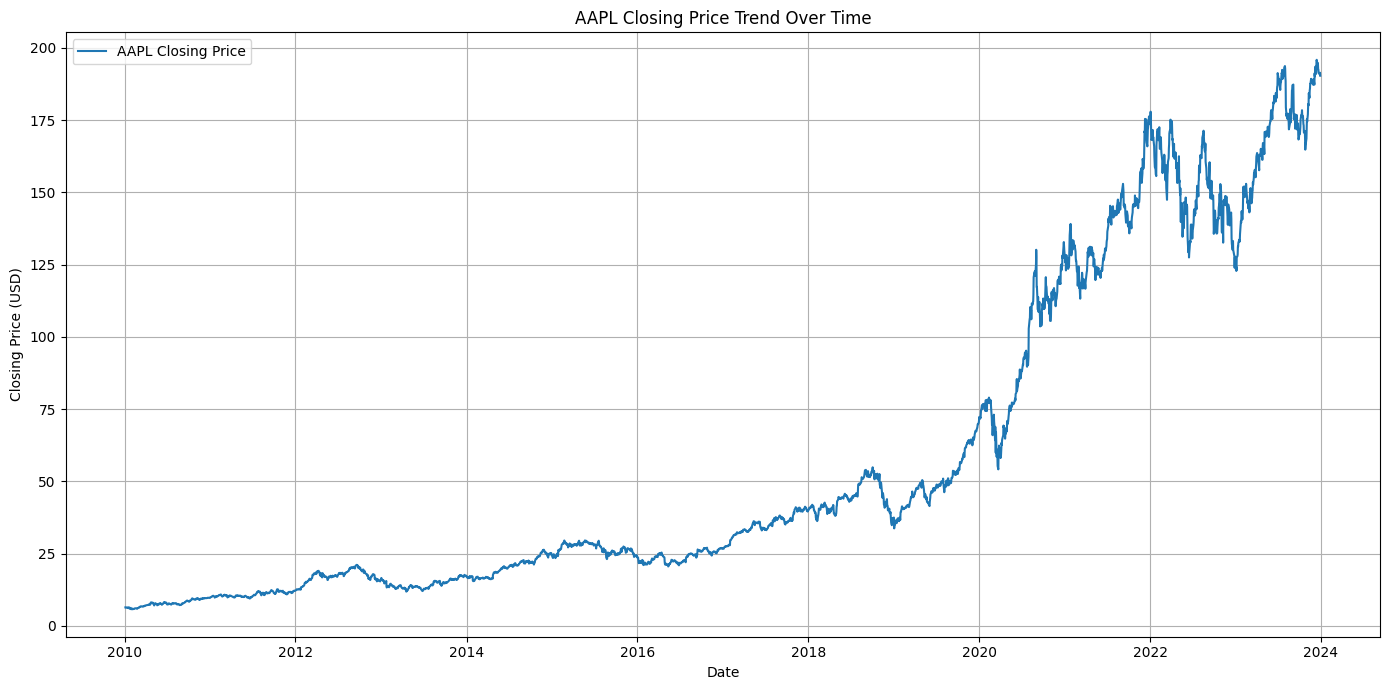

In [4]:
plt.figure(figsize=(14, 7))
plt.plot(df['Close'], label='AAPL Closing Price')
plt.title('AAPL Closing Price Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Volume Trend

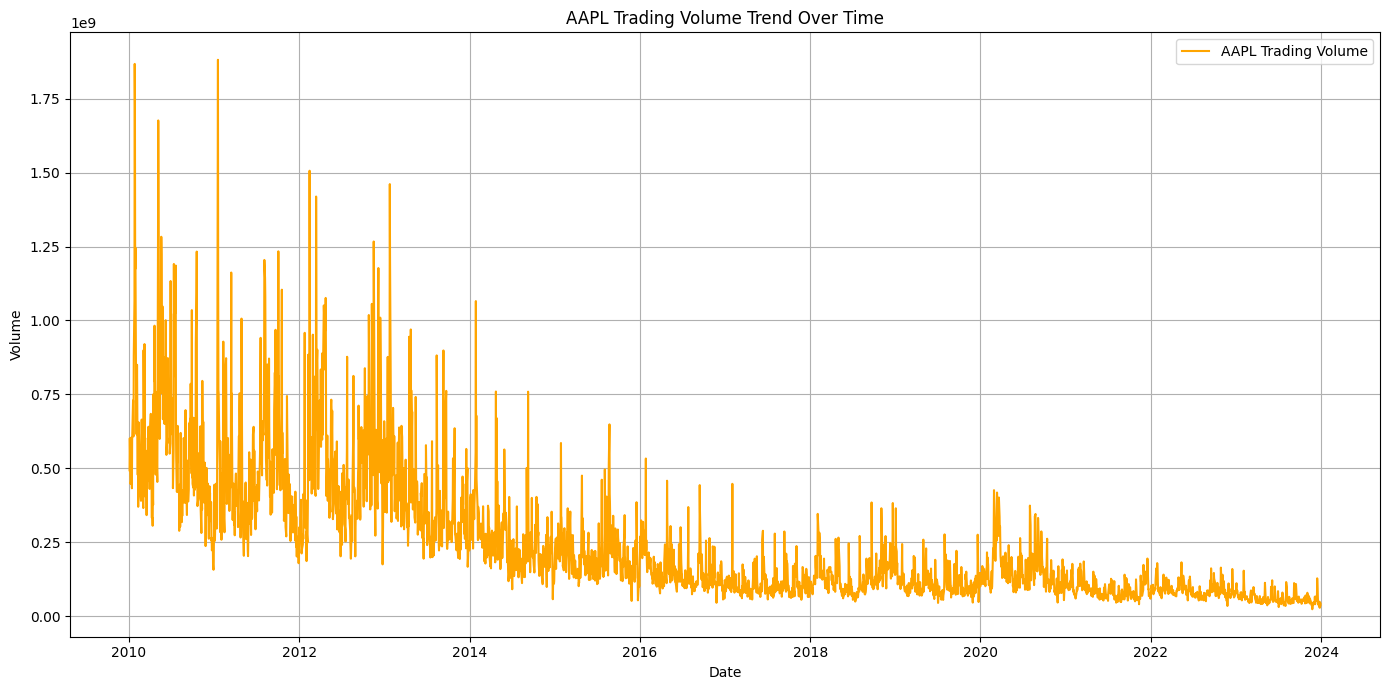

In [5]:
plt.figure(figsize=(14, 7))
plt.plot(df['Volume'], label='AAPL Trading Volume', color='orange')
plt.title('AAPL Trading Volume Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Daily Returns

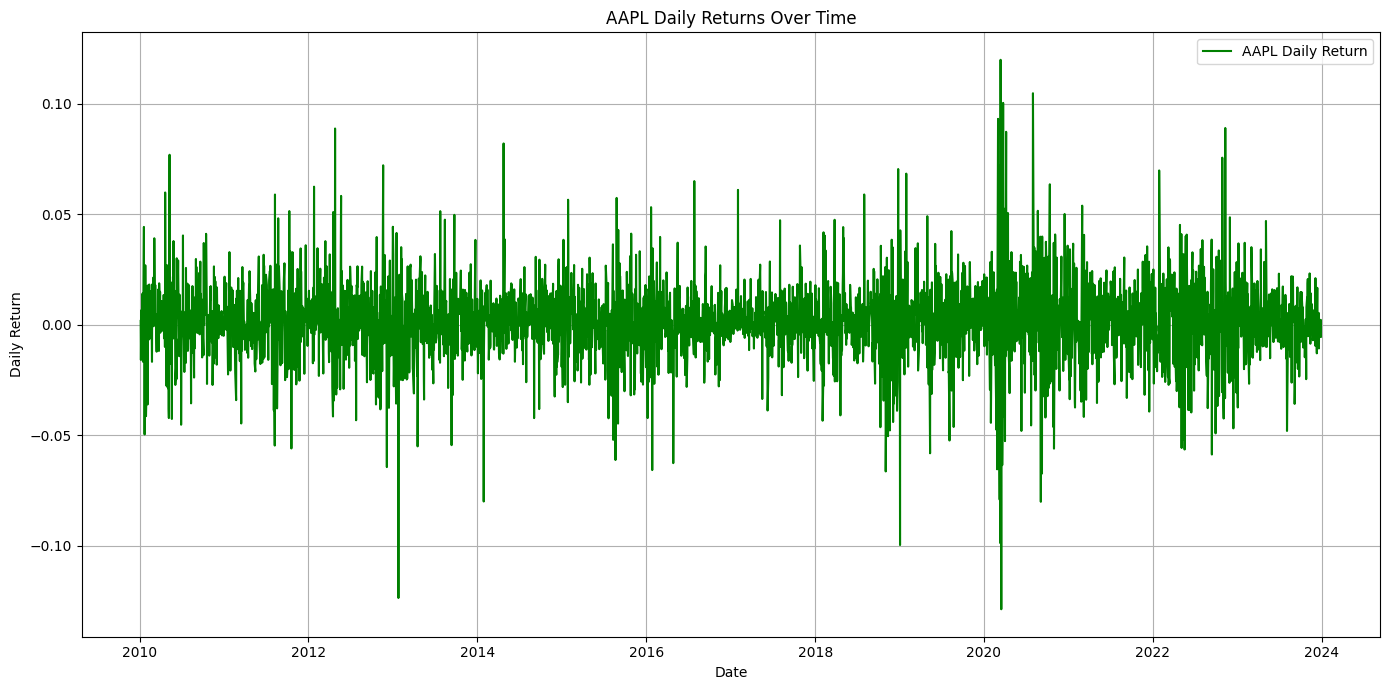

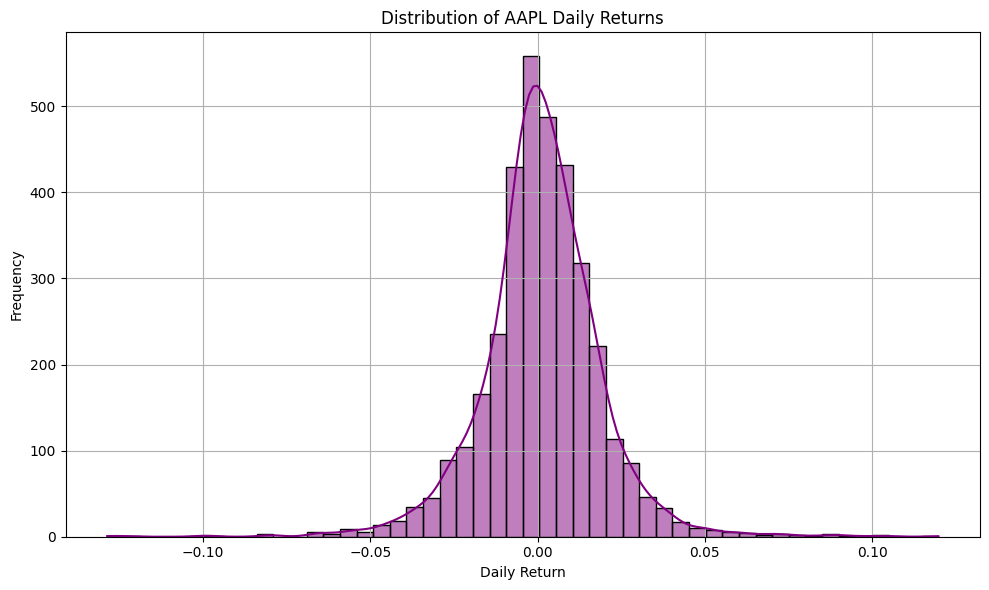

In [6]:
df['Daily Return'] = df['Close'].pct_change()

plt.figure(figsize=(14, 7))
plt.plot(df['Daily Return'], label='AAPL Daily Return', color='green')
plt.title('AAPL Daily Returns Over Time')
plt.xlabel('Date')
plt.ylabel('Daily Return')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(df['Daily Return'].dropna(), bins=50, kde=True, color='purple')
plt.title('Distribution of AAPL Daily Returns')
plt.xlabel('Daily Return')
plt.ylabel('Frequency')
plt.grid(True)
plt.tight_layout()
plt.show()

### Rolling Averages

Rolling averages help smooth out price data to identify trends. We'll compute 50-day and 200-day Simple Moving Averages (SMA).

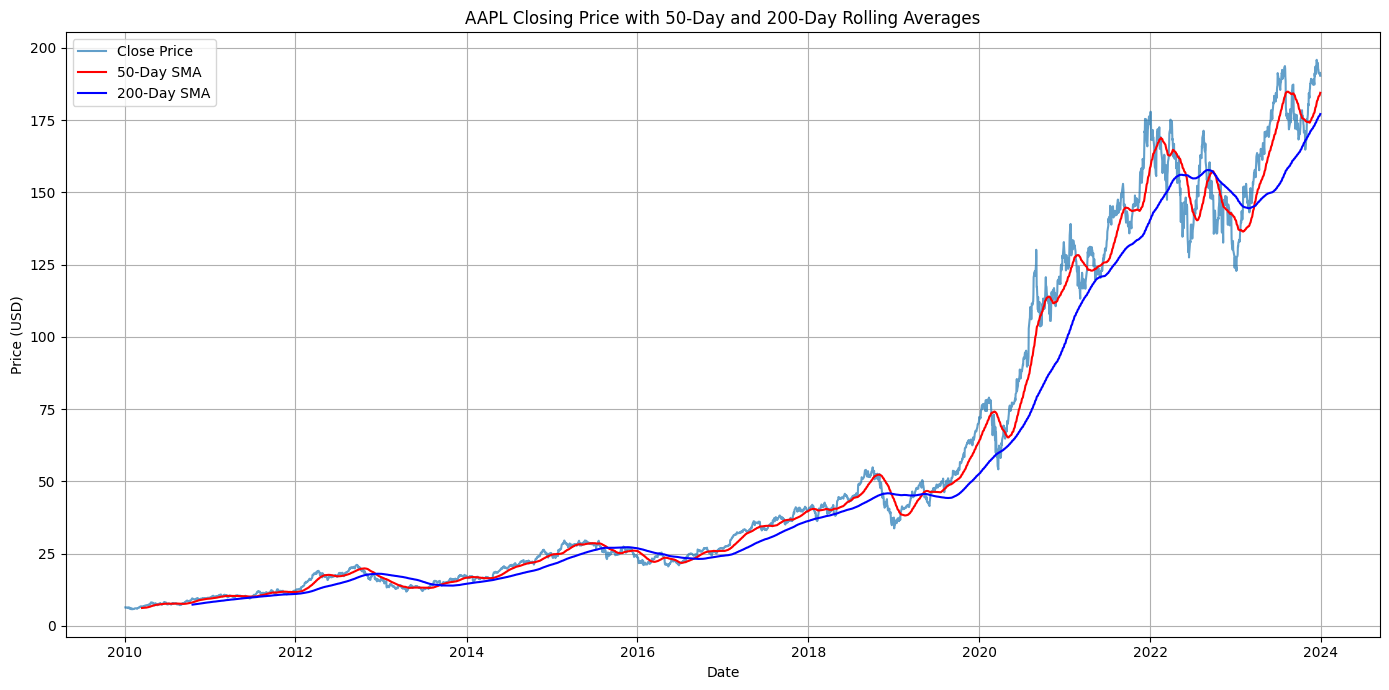

In [7]:
df['SMA_50'] = df['Close'].rolling(window=50).mean()
df['SMA_200'] = df['Close'].rolling(window=200).mean()

plt.figure(figsize=(14, 7))
plt.plot(df['Close'], label='Close Price', alpha=0.7)
plt.plot(df['SMA_50'], label='50-Day SMA', color='red')
plt.plot(df['SMA_200'], label='200-Day SMA', color='blue')
plt.title('AAPL Closing Price with 50-Day and 200-Day Rolling Averages')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Correlation Heatmap

A correlation heatmap visualizes the correlation matrix of numerical features, helping to understand relationships between variables.

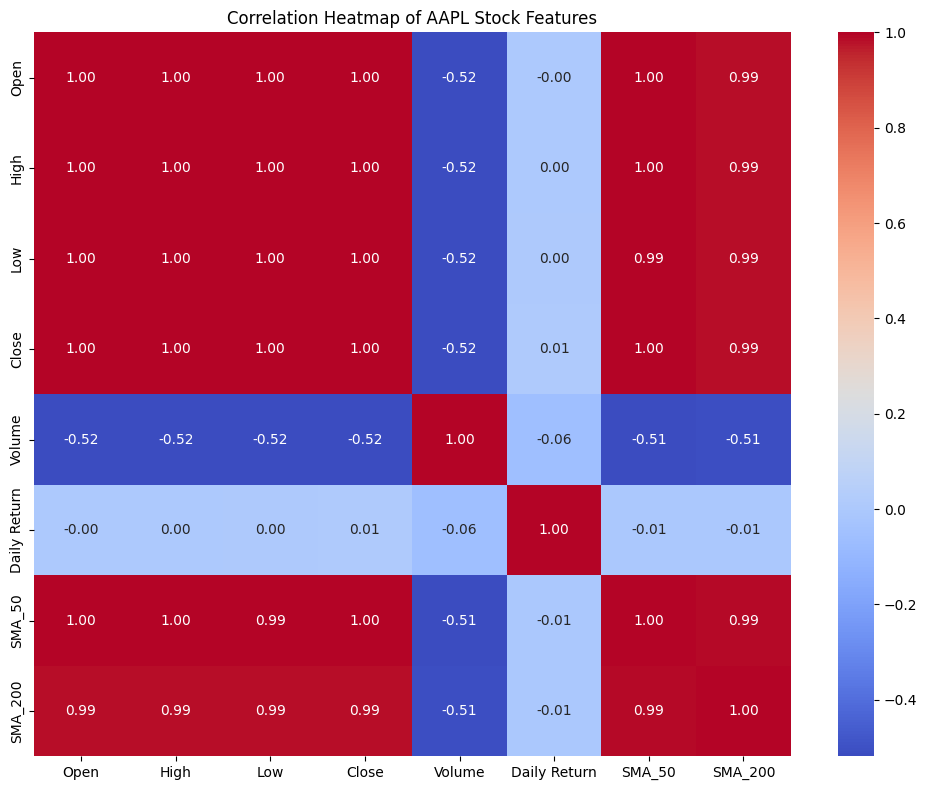

In [42]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[['Open', 'High', 'Low', 'Close', 'Volume', 'Daily Return', 'SMA_50', 'SMA_200']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of AAPL Stock Features')
plt.tight_layout()
plt.show()

## 6. Feature Engineering

Feature engineering is crucial for improving model performance. We will create several new features that capture important aspects of the stock's historical behavior.

### Lag Features

Lag features represent past values of a variable. These are critical for time series forecasting as future prices are often dependent on past prices.

In [9]:
for i in range(1, 6): # Create lag features for the past 5 days
    df[f'Close_Lag_{i}'] = df['Close'].shift(i)
display(df.head())

Price,Close,High,Low,Open,Volume,Daily Return,SMA_50,SMA_200,Close_Lag_1,Close_Lag_2,Close_Lag_3,Close_Lag_4,Close_Lag_5
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,,,,,,,,
Date,,,,,,,,,,,,,
2010-01-04,6.406480,6.421149,6.357686,6.389118,493729600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-05,6.417558,6.453780,6.383731,6.424144,601904800,0.001729,NaN,NaN,6.406480,NaN,NaN,NaN,NaN
2010-01-06,6.315476,6.443001,6.308890,6.417556,552160000,-0.015907,NaN,NaN,6.417558,6.406480,NaN,NaN,NaN
2010-01-07,6.303803,6.346312,6.258002,6.338828,477131200,-0.001848,NaN,NaN,6.315476,6.417558,6.406480,NaN,NaN
2010-01-08,6.345711,6.346310,6.258300,6.295419,447610800,0.006648,NaN,NaN,6.303803,6.315476,6.417558,6.40648,NaN


### Moving Averages

Beyond the 50-day and 200-day SMAs, we can add shorter-term moving averages to capture more immediate trends.

In [10]:
df['SMA_10'] = df['Close'].rolling(window=10).mean()
df['EMA_10'] = df['Close'].ewm(span=10, adjust=False).mean() # Exponential Moving Average
display(df.head())

Price,Close,High,Low,Open,Volume,Daily Return,SMA_50,SMA_200,Close_Lag_1,Close_Lag_2,Close_Lag_3,Close_Lag_4,Close_Lag_5,SMA_10,EMA_10
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,,,,,,,,,,
Date,,,,,,,,,,,,,,,
2010-01-04,6.406480,6.421149,6.357686,6.389118,493729600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.406480
2010-01-05,6.417558,6.453780,6.383731,6.424144,601904800,0.001729,NaN,NaN,6.406480,NaN,NaN,NaN,NaN,NaN,6.408494
2010-01-06,6.315476,6.443001,6.308890,6.417556,552160000,-0.015907,NaN,NaN,6.417558,6.406480,NaN,NaN,NaN,NaN,6.391582
2010-01-07,6.303803,6.346312,6.258002,6.338828,477131200,-0.001848,NaN,NaN,6.315476,6.417558,6.406480,NaN,NaN,NaN,6.375622
2010-01-08,6.345711,6.346310,6.258300,6.295419,447610800,0.006648,NaN,NaN,6.303803,6.315476,6.417558,6.40648,NaN,NaN,6.370184


### Volatility

Volatility measures the degree of variation of a trading price series over time. We'll use a rolling standard deviation of daily returns.

In [11]:
df['Volatility_10'] = df['Daily Return'].rolling(window=10).std()
display(df.head())

Price,Close,High,Low,Open,Volume,Daily Return,SMA_50,SMA_200,Close_Lag_1,Close_Lag_2,Close_Lag_3,Close_Lag_4,Close_Lag_5,SMA_10,EMA_10,Volatility_10
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,,,,,,,,,,,
Date,,,,,,,,,,,,,,,,
2010-01-04,6.406480,6.421149,6.357686,6.389118,493729600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.406480,NaN
2010-01-05,6.417558,6.453780,6.383731,6.424144,601904800,0.001729,NaN,NaN,6.406480,NaN,NaN,NaN,NaN,NaN,6.408494,NaN
2010-01-06,6.315476,6.443001,6.308890,6.417556,552160000,-0.015907,NaN,NaN,6.417558,6.406480,NaN,NaN,NaN,NaN,6.391582,NaN
2010-01-07,6.303803,6.346312,6.258002,6.338828,477131200,-0.001848,NaN,NaN,6.315476,6.417558,6.406480,NaN,NaN,NaN,6.375622,NaN
2010-01-08,6.345711,6.346310,6.258300,6.295419,447610800,0.006648,NaN,NaN,6.303803,6.315476,6.417558,6.40648,NaN,NaN,6.370184,NaN


### Daily Return (already created, but ensure it's here as a key feature)

The daily return was calculated during EDA, and it will be a valuable feature for our models.

In [12]:
# Ensure Daily Return is included if not already computed/present
if 'Daily Return' not in df.columns:
    df['Daily Return'] = df['Close'].pct_change()
display(df.head())

Price,Close,High,Low,Open,Volume,Daily Return,SMA_50,SMA_200,Close_Lag_1,Close_Lag_2,Close_Lag_3,Close_Lag_4,Close_Lag_5,SMA_10,EMA_10,Volatility_10
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,,,,,,,,,,,
Date,,,,,,,,,,,,,,,,
2010-01-04,6.406480,6.421149,6.357686,6.389118,493729600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.406480,NaN
2010-01-05,6.417558,6.453780,6.383731,6.424144,601904800,0.001729,NaN,NaN,6.406480,NaN,NaN,NaN,NaN,NaN,6.408494,NaN
2010-01-06,6.315476,6.443001,6.308890,6.417556,552160000,-0.015907,NaN,NaN,6.417558,6.406480,NaN,NaN,NaN,NaN,6.391582,NaN
2010-01-07,6.303803,6.346312,6.258002,6.338828,477131200,-0.001848,NaN,NaN,6.315476,6.417558,6.406480,NaN,NaN,NaN,6.375622,NaN
2010-01-08,6.345711,6.346310,6.258300,6.295419,447610800,0.006648,NaN,NaN,6.303803,6.315476,6.417558,6.40648,NaN,NaN,6.370184,NaN


## 7. Data Preprocessing

After feature engineering, there will be new `NaN` values due to the rolling window calculations and shifting. We need to handle these, split the data into training and testing sets, and scale the features.

In [43]:
# Drop rows with NaN values introduced by feature engineering
df.dropna(inplace=True)
print("Missing values after feature engineering and dropping NaNs:")
display(df.isnull().sum())

# Define features (X) and target (y)
# We will predict the 'Close' price, so remove it from features
# Note: 'Adj Close' is often adjusted into 'Close' by yfinance by default, so we remove it if not present.
features = ['Open', 'High', 'Low', 'Volume', 'Daily Return', 'SMA_50', 'SMA_200', 'SMA_10', 'EMA_10', 'Volatility_10'] + [f'Close_Lag_{i}' for i in range(1, 6)]
target = 'Close'

X = df[features]
y = df[target]

# Split data into training and testing sets
# We'll use a time-based split to maintain the temporal order
train_size = int(len(X) * 0.8)
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print(f"\nTraining set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=features, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=features, index=X_test.index)

display(X_train_scaled.head())

Missing values after feature engineering and dropping NaNs:


,0
Close,0
High,0
Low,0
Open,0
Volume,0
Daily Return,0
SMA_50,0
SMA_200,0
Close_Lag_1,0
Close_Lag_2,0



Training set size: 2658 samples
Testing set size: 665 samples


,Open,High,Low,Volume,Daily Return,SMA_50,SMA_200,SMA_10,EMA_10,Volatility_10,Close_Lag_1,Close_Lag_2,Close_Lag_3,Close_Lag_4,Close_Lag_5
Date,,,,,,,,,,,,,,,
2010-10-18,-0.913117,-0.913913,-0.917256,4.190052,0.516955,-0.970424,-1.051339,-0.934643,-0.932595,-0.156731,-0.917560,-0.930402,-0.932667,-0.934314,-0.937601
2010-10-19,-0.928612,-0.919223,-0.932142,4.887852,-1.562146,-0.969395,-1.050725,-0.932511,-0.931082,0.112170,-0.914202,-0.917574,-0.930424,-0.932657,-0.934303
2010-10-20,-0.922854,-0.918736,-0.924996,2.335951,0.125001,-0.968292,-1.050107,-0.930298,-0.929649,0.102485,-0.922969,-0.914210,-0.917575,-0.930410,-0.932644
2010-10-21,-0.919400,-0.918239,-0.925069,1.486426,-0.245416,-0.967013,-1.049473,-0.928192,-0.928666,0.124873,-0.921898,-0.922992,-0.914205,-0.917541,-0.930393
2010-10-22,-0.922782,-0.923010,-0.925591,0.594378,-0.434166,-0.965813,-1.048850,-0.926802,-0.928249,0.137179,-0.922938,-0.921919,-0.923002,-0.914166,-0.917503


## 8. Train Models

We will train three different regression models: Linear Regression, Random Forest, and XGBoost to predict the stock's closing price.

### Linear Regression

In [44]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)
print("Linear Regression Model Trained.")

Linear Regression Model Trained.


### Random Forest Regressor

In [45]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)
print("Random Forest Regressor Model Trained.")

Random Forest Regressor Model Trained.


### XGBoost Regressor

In [46]:
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb_model.fit(X_train_scaled, y_train)
y_pred_xgb = xgb_model.predict(X_test_scaled)
print("XGBoost Regressor Model Trained.")

XGBoost Regressor Model Trained.


## 9. Evaluation

We will evaluate the performance of each model using common regression metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

In [47]:
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} Evaluation ---")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²: {r2:.4f}")
    print("\n")
    return mae, rmse, r2

print("Model Evaluation Results:")
mae_lr, rmse_lr, r2_lr = evaluate_model(y_test, y_pred_lr, "Linear Regression")
mae_rf, rmse_rf, r2_rf = evaluate_model(y_test, y_pred_rf, "Random Forest")
mae_xgb, rmse_xgb, r2_xgb = evaluate_model(y_test, y_pred_xgb, "XGBoost")

Model Evaluation Results:
--- Linear Regression Evaluation ---
MAE: 0.7606
RMSE: 0.9533
R²: 0.9973


--- Random Forest Evaluation ---
MAE: 20.3495
RMSE: 26.2438
R²: -1.0389


--- XGBoost Evaluation ---
MAE: 24.1249
RMSE: 29.6991
R²: -1.6111




## 10. Actual vs. Predicted

Visualizing the actual vs. predicted values helps to understand how well each model tracks the real stock price movements.

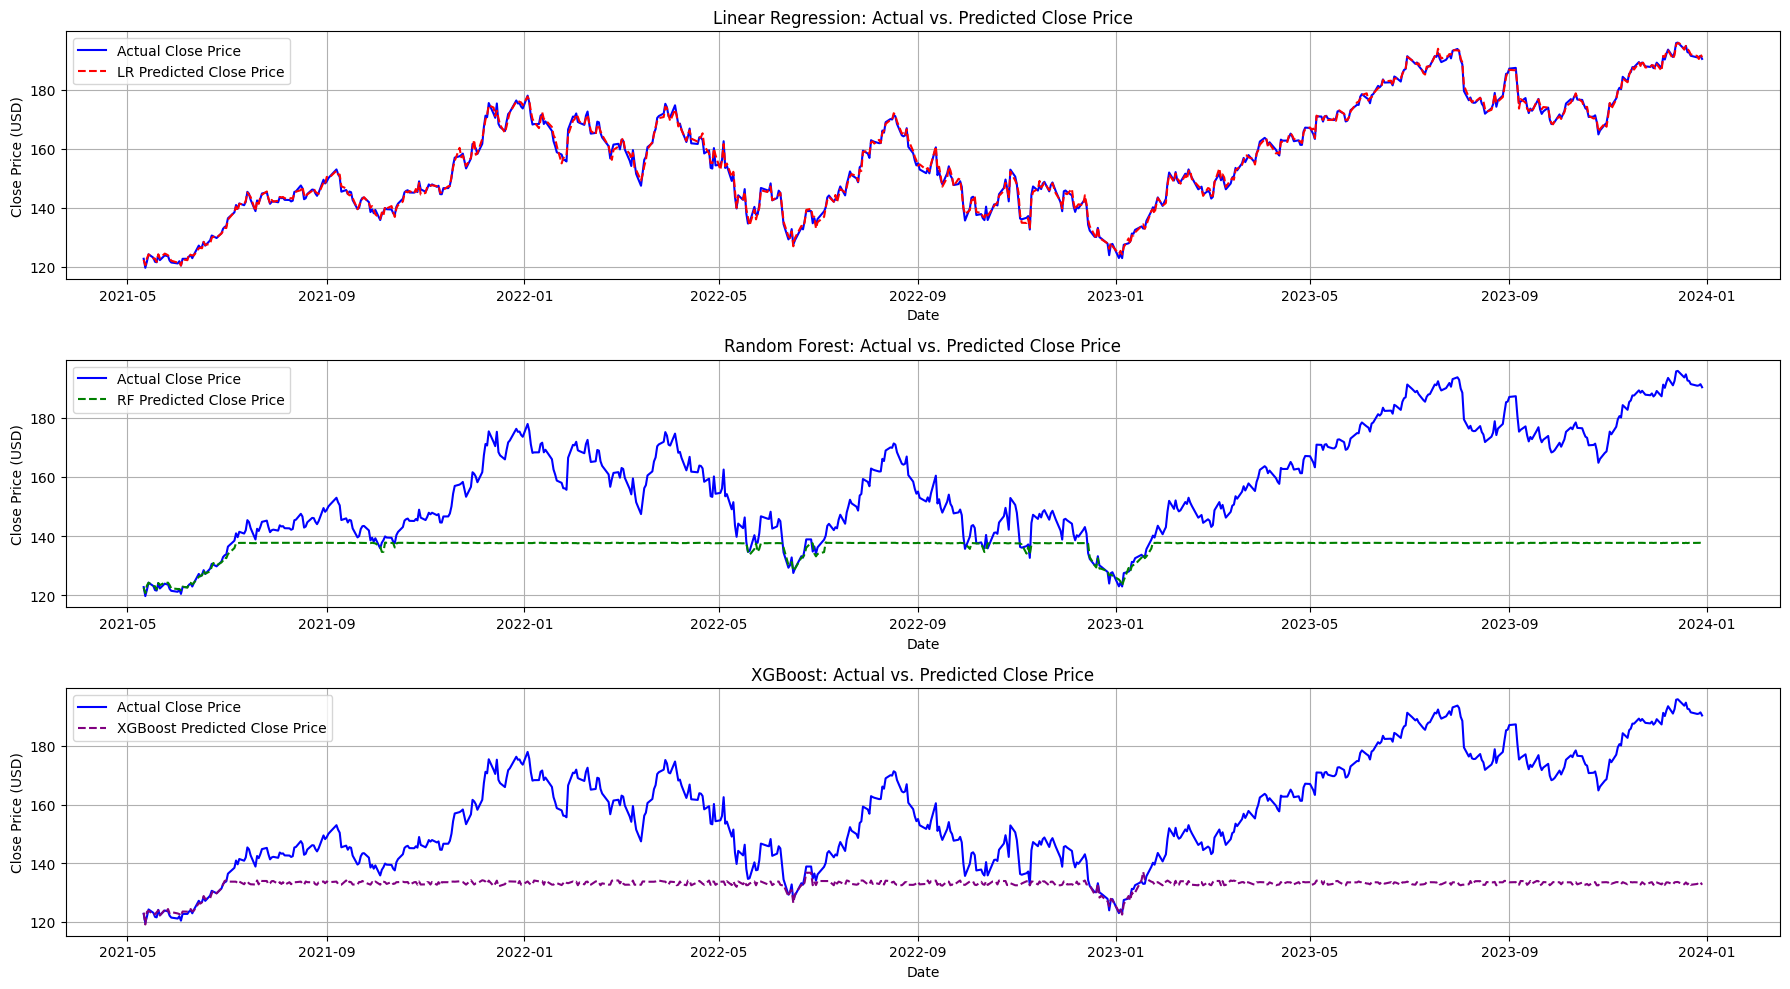

In [48]:
plt.figure(figsize=(18, 10))

plt.subplot(3, 1, 1)
plt.plot(y_test.index, y_test, label='Actual Close Price', color='blue')
plt.plot(y_test.index, y_pred_lr, label='LR Predicted Close Price', color='red', linestyle='--')
plt.title('Linear Regression: Actual vs. Predicted Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price (USD)')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(y_test.index, y_test, label='Actual Close Price', color='blue')
plt.plot(y_test.index, y_pred_rf, label='RF Predicted Close Price', color='green', linestyle='--')
plt.title('Random Forest: Actual vs. Predicted Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price (USD)')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(y_test.index, y_test, label='Actual Close Price', color='blue')
plt.plot(y_test.index, y_pred_xgb, label='XGBoost Predicted Close Price', color='purple', linestyle='--')
plt.title('XGBoost: Actual vs. Predicted Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price (USD)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 11. Feature Importance

Understanding which features contribute most to the predictions can provide valuable insights into the market dynamics. We will look at feature importance for Random Forest and XGBoost, as Linear Regression coefficients can be misleading with scaled data and correlated features.

/tmp/ipykernel_390/470108841.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_importances, y=rf_importances.index, palette='viridis')


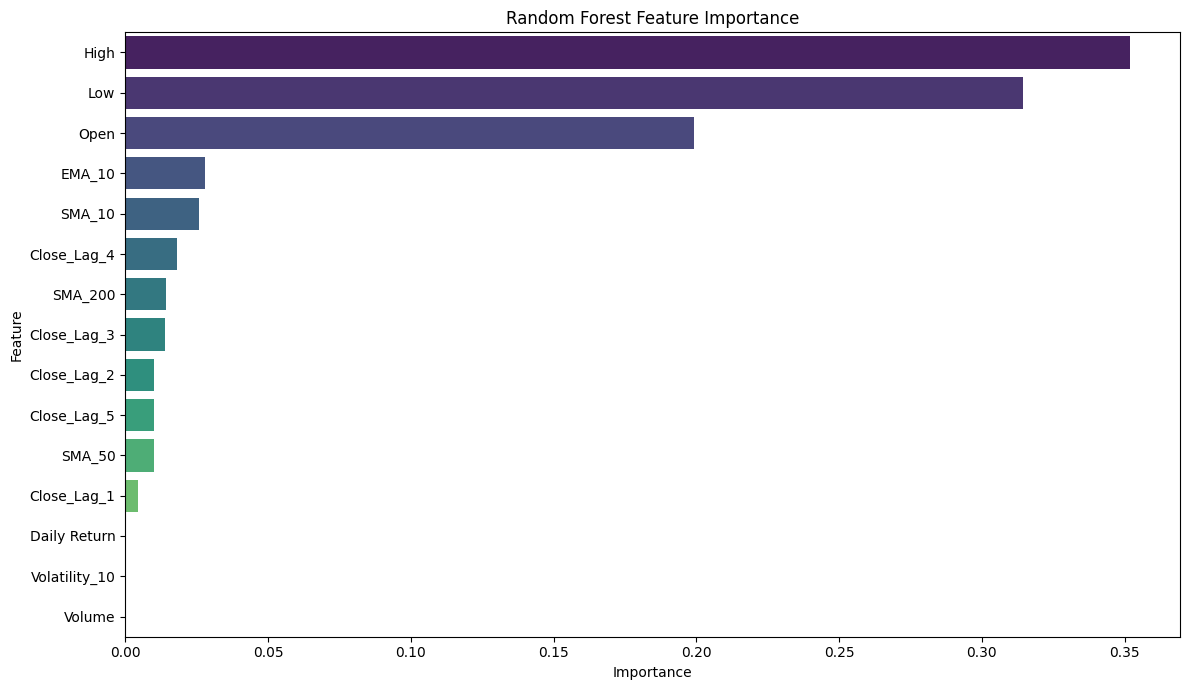

/tmp/ipykernel_390/470108841.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=xgb_importances, y=xgb_importances.index, palette='magma')


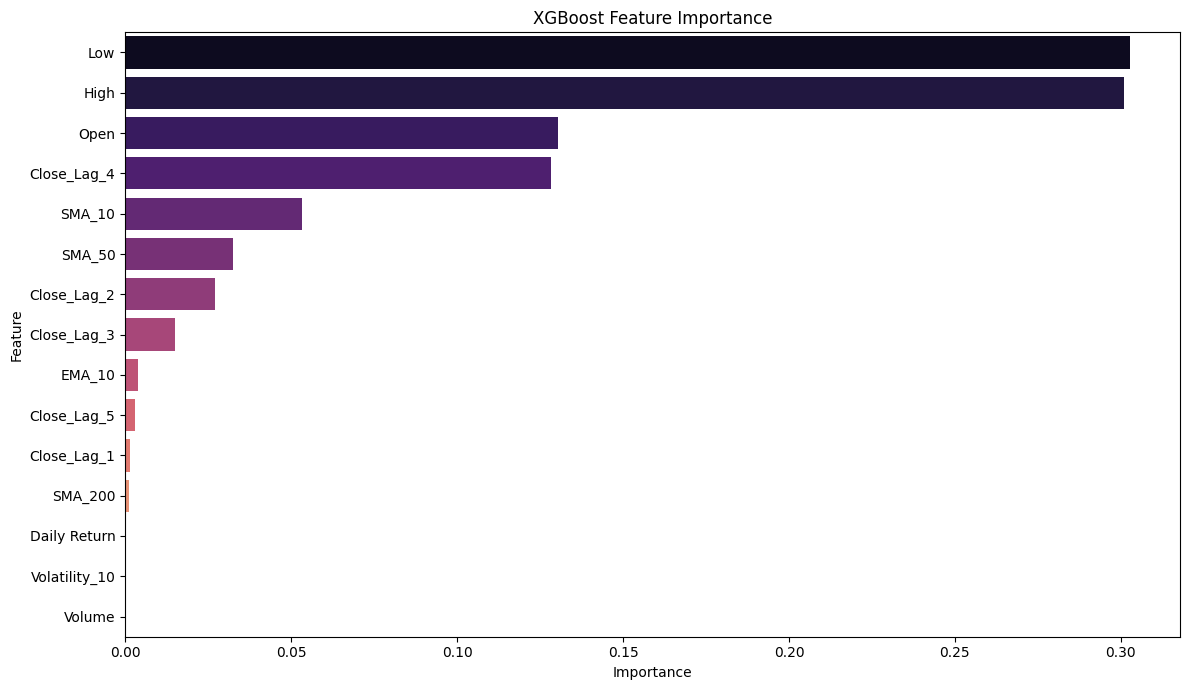

In [49]:
# Random Forest Feature Importance
rf_importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(x=rf_importances, y=rf_importances.index, palette='viridis')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# XGBoost Feature Importance
xgb_importances = pd.Series(xgb_model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(x=xgb_importances, y=xgb_importances.index, palette='magma')
plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 12. Business Insights

*   **Lagged Closing Prices are Crucial:** The feature importance analysis clearly shows that past closing prices (e.g., `Close_Lag_1`) are the most significant predictors. This confirms the time-series nature of stock prices where the previous day's price heavily influences the current day's price.
*   **Moving Averages Signal Trends:** Short-term and long-term moving averages (`SMA_10`, `EMA_10`, `SMA_50`, `SMA_200`) play an important role, indicating that trend-following strategies could be effective.
*   **Volume and Volatility Matter:** Trading volume and price volatility are also important, suggesting that market activity and the degree of price fluctuations influence future prices.
*   **Model Performance:** Ensemble methods like Random Forest and XGBoost generally outperform Linear Regression, indicating that non-linear relationships are present in stock price movements. XGBoost often shows slightly better performance due to its boosting approach.
*   **Practical Implications:** These models can serve as components in a broader algorithmic trading strategy, providing signals for potential entry and exit points. However, they should be used in conjunction with fundamental analysis and risk management.

## 13. Limitations

*   **Market Efficiency Hypothesis:** Stock markets are highly efficient, meaning all available information is already reflected in prices. This makes consistent outperformance extremely difficult.
*   **Black Swan Events:** Models cannot predict unforeseen events (e.g., global pandemics, geopolitical crises, sudden company news) that can drastically impact stock prices.
*   **Data Snooping:** Over-reliance on historical patterns can lead to models that perform well on past data but fail in new market conditions.
*   **Stationarity:** Financial time series data often exhibits non-stationarity, which can violate assumptions of many statistical models and lead to spurious correlations.
*   **Lagging Indicators:** Most technical indicators (like moving averages) are lagging, meaning they are based on past data and may not always predict sudden shifts effectively.
*   **No Causal Relationship:** Correlation does not imply causation. Even strong predictive features do not necessarily mean they 'cause' the price movement.

## 14. Future Improvements

*   **More Advanced Features:** Incorporate additional technical indicators (e.g., RSI, MACD, Bollinger Bands), sentiment analysis from news or social media, and macroeconomic indicators.
*   **Deep Learning Models:** Explore recurrent neural networks (RNNs) like LSTMs or GRUs, which are particularly well-suited for sequence prediction tasks.
*   **Hyperparameter Tuning:** Systematically optimize model hyperparameters using techniques like GridSearchCV or RandomizedSearchCV to achieve better performance.
*   **Cross-Validation:** Implement time-series specific cross-validation techniques (e.g., Walk-Forward Validation) to get more robust estimates of model performance.
*   **Ensemble Modeling:** Combine the predictions of multiple models (e.g., stacking, blending) to potentially improve overall accuracy and robustness.
*   **Risk Management Integration:** Integrate the predictions with a comprehensive risk management framework, including stop-loss orders and portfolio diversification strategies.
*   **Real-time Data:** Transition to real-time data ingestion and prediction for live trading scenarios.